In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Here's an example of how to load a dataset from the UCI Machine Learning Repository using pandas. We'll use the "Adult" dataset.

In [2]:
# URL for the Adult dataset (data file)
url_data = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.data"

# Column names for the dataset (as the data file doesn't have headers)
column_names = [
    "age", "workclass", "fnlwgt", "education", "education-num",
    "marital-status", "occupation", "relationship", "race", "sex",
    "capital-gain", "capital-loss", "hours-per-week", "native-country", "income"
]

# Load the dataset
adult_df = pd.read_csv(url_data, header=None, names=column_names, na_values="?")

# Display the first few rows and some info
display(adult_df.head())
display(adult_df.info())

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education-num   32561 non-null  int64 
 5   marital-status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital-gain    32561 non-null  int64 
 11  capital-loss    32561 non-null  int64 
 12  hours-per-week  32561 non-null  int64 
 13  native-country  32561 non-null  object
 14  income          32561 non-null  object
dtypes: int64(6), object(9)
memory usage: 3.7+ MB


None

In [4]:
adult_df.isna().sum()


,0
age,0
workclass,0
fnlwgt,0
education,0
education-num,0
marital-status,0
occupation,0
relationship,0
race,0
sex,0



--- Information for column: age ---
count    32561.000000
mean        38.581647
std         13.640433
min         17.000000
25%         28.000000
50%         37.000000
75%         48.000000
max         90.000000
Name: age, dtype: float64
Mode:
0    36
Name: age, dtype: int64


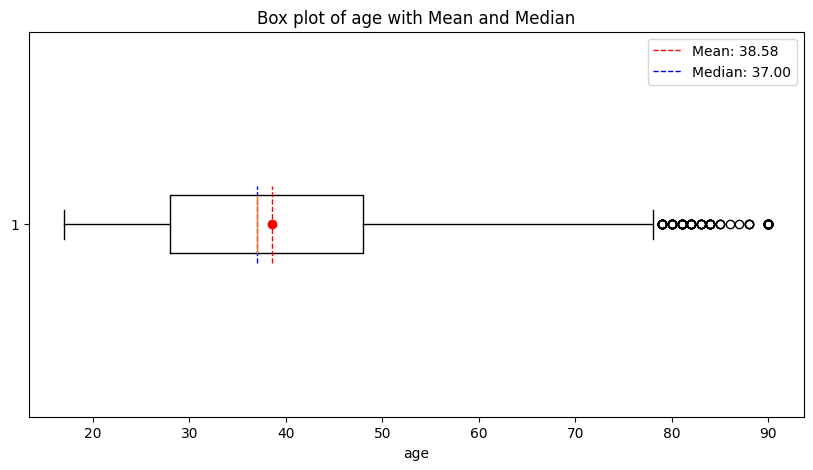


--- Information for column: fnlwgt ---
count    3.256100e+04
mean     1.897784e+05
std      1.055500e+05
min      1.228500e+04
25%      1.178270e+05
50%      1.783560e+05
75%      2.370510e+05
max      1.484705e+06
Name: fnlwgt, dtype: float64
Mode:
0    123011
1    164190
2    203488
Name: fnlwgt, dtype: int64


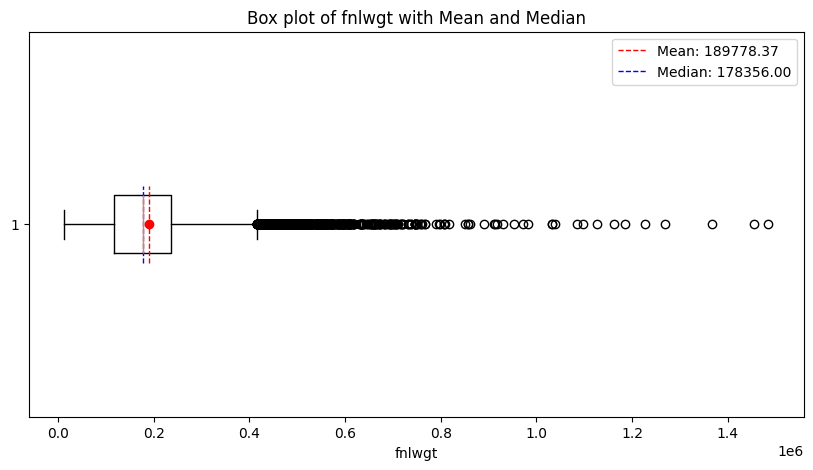


--- Information for column: education-num ---
count    32561.000000
mean        10.080679
std          2.572720
min          1.000000
25%          9.000000
50%         10.000000
75%         12.000000
max         16.000000
Name: education-num, dtype: float64
Mode:
0    9
Name: education-num, dtype: int64


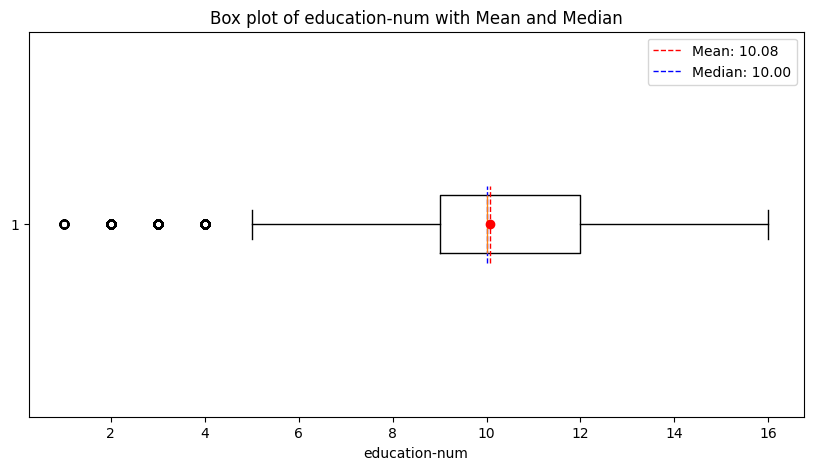


--- Information for column: capital-gain ---
count    32561.000000
mean      1077.648844
std       7385.292085
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max      99999.000000
Name: capital-gain, dtype: float64
Mode:
0    0
Name: capital-gain, dtype: int64


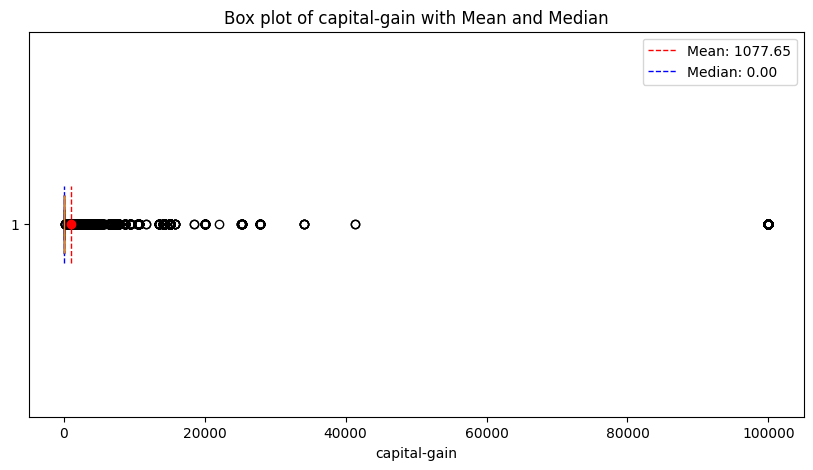


--- Information for column: capital-loss ---
count    32561.000000
mean        87.303830
std        402.960219
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max       4356.000000
Name: capital-loss, dtype: float64
Mode:
0    0
Name: capital-loss, dtype: int64


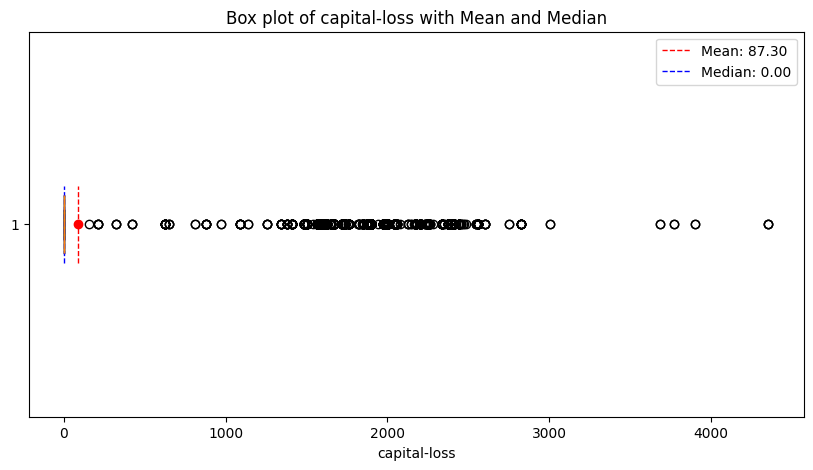


--- Information for column: hours-per-week ---
count    32561.000000
mean        40.437456
std         12.347429
min          1.000000
25%         40.000000
50%         40.000000
75%         45.000000
max         99.000000
Name: hours-per-week, dtype: float64
Mode:
0    40
Name: hours-per-week, dtype: int64


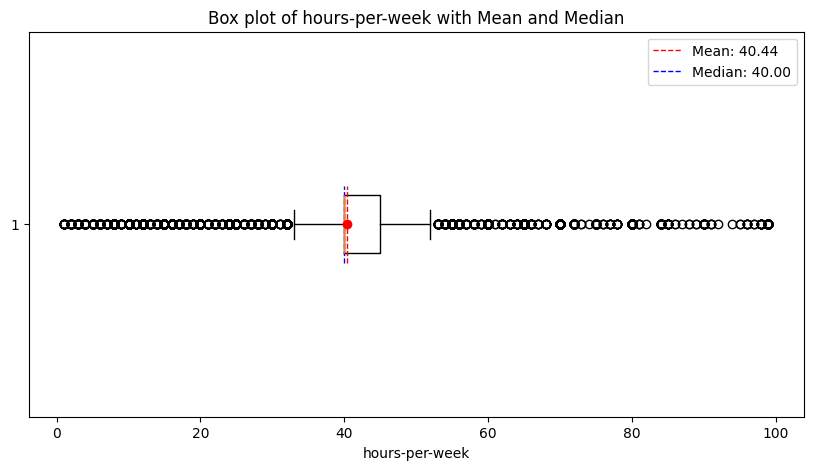

In [14]:
for col in column_names:
    if adult_df[col].dtype == int or adult_df[col].dtype == float:
        print(f"\n--- Information for column: {col} ---")
        description = adult_df[col].describe()
        print(description)
        try:
            mode_val = adult_df[col].mode()
            if not mode_val.empty:
                print(f"Mode:\n{mode_val}")
            else:
                print("Mode: Not available")
        except Exception as e:
             print(f"Could not compute mode: {e}")


        plt.figure(figsize=(10,5))
        plt.boxplot(x=adult_df[col], vert=False, showmeans=True, data=adult_df, meanprops={"marker":"o", "markerfacecolor":"red", "markeredgecolor":"red"})
        plt.xlabel(col)
        plt.title(f"Box plot of {col} with Mean and Median")

        # Add shorter vertical lines for mean and median with labels
        mean_val = description['mean']
        median_val = description['50%']

        # The y-coordinates for horizontal box plots are typically around 1.
        # We can draw short vertical lines around this y-coordinate.
        y_coord = 1
        line_length = 0.1 # Adjust this value to change the length of the lines

        plt.vlines(mean_val, y_coord - line_length, y_coord + line_length, color='red', linestyle='dashed', linewidth=1, label=f'Mean: {mean_val:.2f}')
        plt.vlines(median_val, y_coord - line_length, y_coord + line_length, color='blue', linestyle='dashed', linewidth=1, label=f'Median: {median_val:.2f}')
        plt.legend()

        plt.show()